# 03 - Model Building and Training

## Project: Banking Loan Default Prediction

### Objectives
1. Load processed training and testing datasets.
2. Train Logistic Regression.
3. Train Decision Tree.
4. Train Random Forest.
5. Compare model performance.
6. Save trained models.

In [2]:
# Reload processed datasets

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

# Locate project directory
if (Path.cwd() / "data").exists():
    PROJECT_ROOT = Path.cwd()
elif (Path.cwd().parent / "data").exists():
    PROJECT_ROOT = Path.cwd().parent
else:
    raise FileNotFoundError("Project root not found!")

# Load processed datasets
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze()

print("Datasets loaded successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Datasets loaded successfully!
X_train: (80000, 50)
X_test: (20000, 50)
y_train: (80000,)
y_test: (20000,)


In [1]:
# Step 7.2 - Import Libraries

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Locate project directory
if (Path.cwd() / "data").exists():
    PROJECT_ROOT = Path.cwd()
elif (Path.cwd().parent / "data").exists():
    PROJECT_ROOT = Path.cwd().parent
else:
    raise FileNotFoundError("Project root not found!")

# Load processed datasets
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze()

# Display dataset information
print("Processed datasets loaded successfully!")

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

Processed datasets loaded successfully!

X_train: (80000, 50)
X_test: (20000, 50)
y_train: (80000,)
y_test: (20000,)

Training target distribution:
default_flag
0    52921
1    27079
Name: count, dtype: int64


## Step 7.3 - Logistic Regression

Train a Logistic Regression classification model to predict whether a loan applicant will default.

In [2]:
# Step 7.3 - Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

# Train the model
print("Training Logistic Regression Model...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Training Completed!")

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred_logistic)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Training Logistic Regression Model...
Logistic Regression Model Training Completed!

Model Accuracy: 74.64 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.76      0.80     13230
           1       0.61      0.71      0.66      6770

    accuracy                           0.75     20000
   macro avg       0.72      0.74      0.73     20000
weighted avg       0.76      0.75      0.75     20000


Confusion Matrix:
[[10110  3120]
 [ 1951  4819]]


## Step 7.4 - Decision Tree Classifier

Train a Decision Tree classification model to predict loan defaults.

In [3]:
# Step 7.4 - Train Decision Tree Model

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Train model
print("Training Decision Tree Model...")

decision_tree_model.fit(X_train, y_train)

print("Decision Tree Model Training Completed!")

# Generate predictions
y_pred_tree = decision_tree_model.predict(X_test)

# Evaluate model
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("\nModel Accuracy:", round(accuracy_tree * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Training Decision Tree Model...
Decision Tree Model Training Completed!

Model Accuracy: 73.42 %

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.77      0.79     13230
           1       0.60      0.67      0.63      6770

    accuracy                           0.73     20000
   macro avg       0.71      0.72      0.71     20000
weighted avg       0.74      0.73      0.74     20000


Confusion Matrix:
[[10151  3079]
 [ 2236  4534]]


## Step 7.5 - Random Forest Classifier

Train a Random Forest classification model to predict loan defaults.

In [4]:
# Step 7.5 - Train Random Forest Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training Random Forest Model...")

random_forest_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

# Evaluate model
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("\nModel Accuracy:", round(accuracy_rf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Training Random Forest Model...
Random Forest Model Training Completed!

Model Accuracy: 75.03 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80     13230
           1       0.62      0.70      0.65      6770

    accuracy                           0.75     20000
   macro avg       0.72      0.74      0.73     20000
weighted avg       0.76      0.75      0.75     20000


Confusion Matrix:
[[10300  2930]
 [ 2064  4706]]


## Step 7.6 - Model Performance Comparison

Compare Logistic Regression, Decision Tree and Random Forest using accuracy, precision, recall and F1-score.

In [5]:
# Step 7.6 - Model Performance Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect model performance
models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf
}

comparison_results = []

for model_name, predictions in models.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# Create comparison DataFrame
model_comparison = pd.DataFrame(comparison_results)

# Display results
print("MODEL PERFORMANCE COMPARISON")

display(
    model_comparison
    .sort_values(by="F1 Score", ascending=False)
    .round(4)
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7464,0.6070,0.7118,0.6552
2,Random Forest,0.7503,0.6163,0.6951,0.6533
1,Decision Tree,0.7342,0.5956,0.6697,0.6305


## Step 7.7 - Save Trained Models

Save the trained Logistic Regression, Decision Tree and Random Forest models for future use.

In [6]:
# Step 7.7 - Save Trained Models

import joblib
from pathlib import Path

# Create model directory
MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save Logistic Regression
joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression.pkl"
)

# Save Decision Tree
joblib.dump(
    decision_tree_model,
    MODEL_DIR / "decision_tree.pkl"
)

# Save Random Forest
joblib.dump(
    random_forest_model,
    MODEL_DIR / "random_forest.pkl"
)

print("All trained models saved successfully!")

print("\nSaved model files:")

for file in sorted(MODEL_DIR.glob("*.pkl")):
    print(file.name)

All trained models saved successfully!

Saved model files:
categorical_imputer.pkl
decision_tree.pkl
logistic_regression.pkl
numerical_imputer.pkl
onehot_encoder.pkl
random_forest.pkl
standard_scaler.pkl


# 04 - Advanced Model Evaluation

## Step 8.1 - ROC-AUC and Precision-Recall AUC

Evaluate the classification models using ROC-AUC and Average Precision scores.

In [7]:
# Step 8.1 - Advanced Model Evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Collect trained models
trained_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Store evaluation results
advanced_results = []

for model_name, model in trained_models.items():

    # Predict default probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    advanced_results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

# Create comparison table
advanced_comparison = pd.DataFrame(advanced_results)

print("ADVANCED MODEL EVALUATION RESULTS")

display(
    advanced_comparison
    .sort_values(by="ROC-AUC", ascending=False)
    .round(4)
)

ADVANCED MODEL EVALUATION RESULTS


,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.8175,0.7294
2,Random Forest,0.8135,0.7221
1,Decision Tree,0.7892,0.6818


## Step 8.2 - ROC Curve Comparison

Visualise the ROC curves of all three classification models.

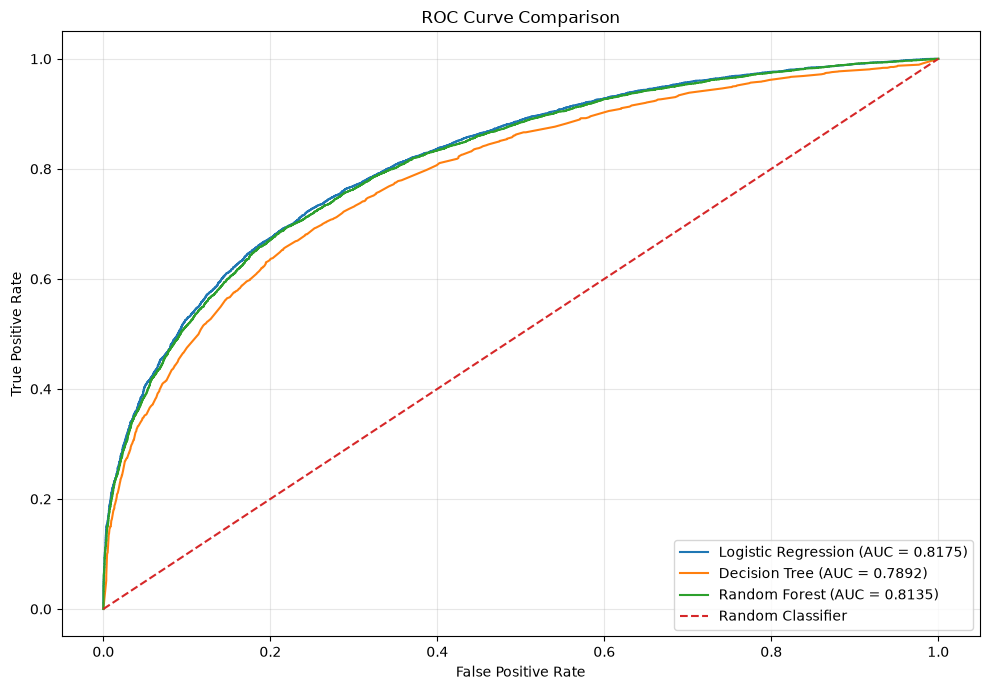

In [8]:
# Step 8.2 - Plot ROC Curves

import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

for model_name, model in trained_models.items():

    # Predict probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Calculate AUC
    auc_score = roc_auc_score(y_test, y_prob)

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 8.3 - Precision-Recall Curve Comparison

Compare precision and recall across different classification thresholds.

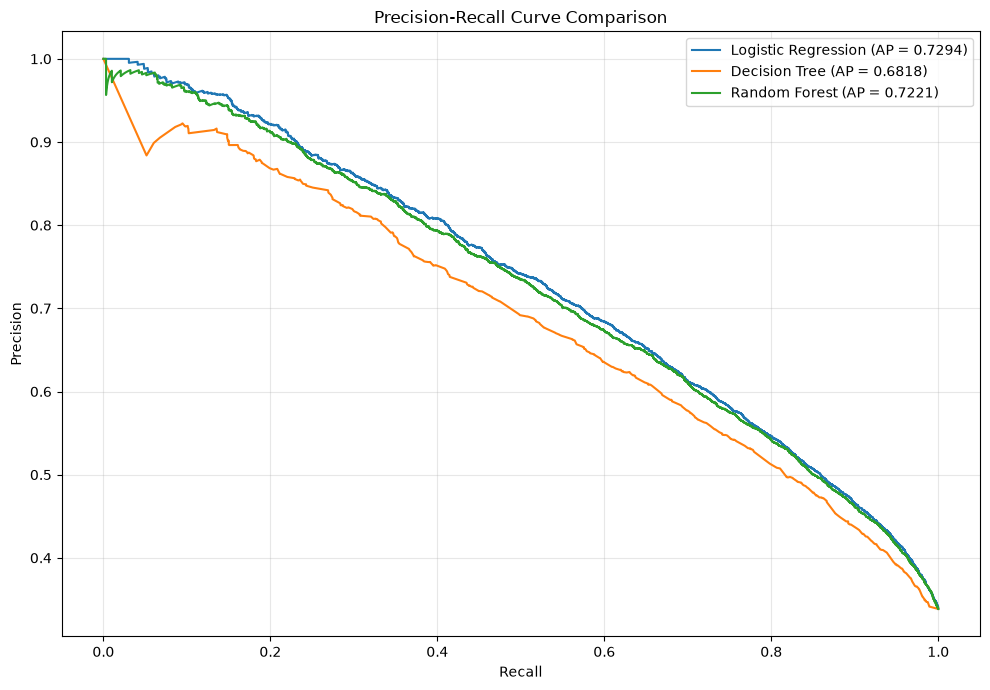

In [9]:
# Step 8.3 - Plot Precision-Recall Curves

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for model_name, model in trained_models.items():

    # Predict probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate precision-recall curve
    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_prob
    )

    # Calculate Average Precision
    ap_score = average_precision_score(y_test, y_prob)

    # Plot curve
    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap_score:.4f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend(loc="best")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 8.4 - Confusion Matrix Visualisation

Visualise and compare the confusion matrices of all three classification models.

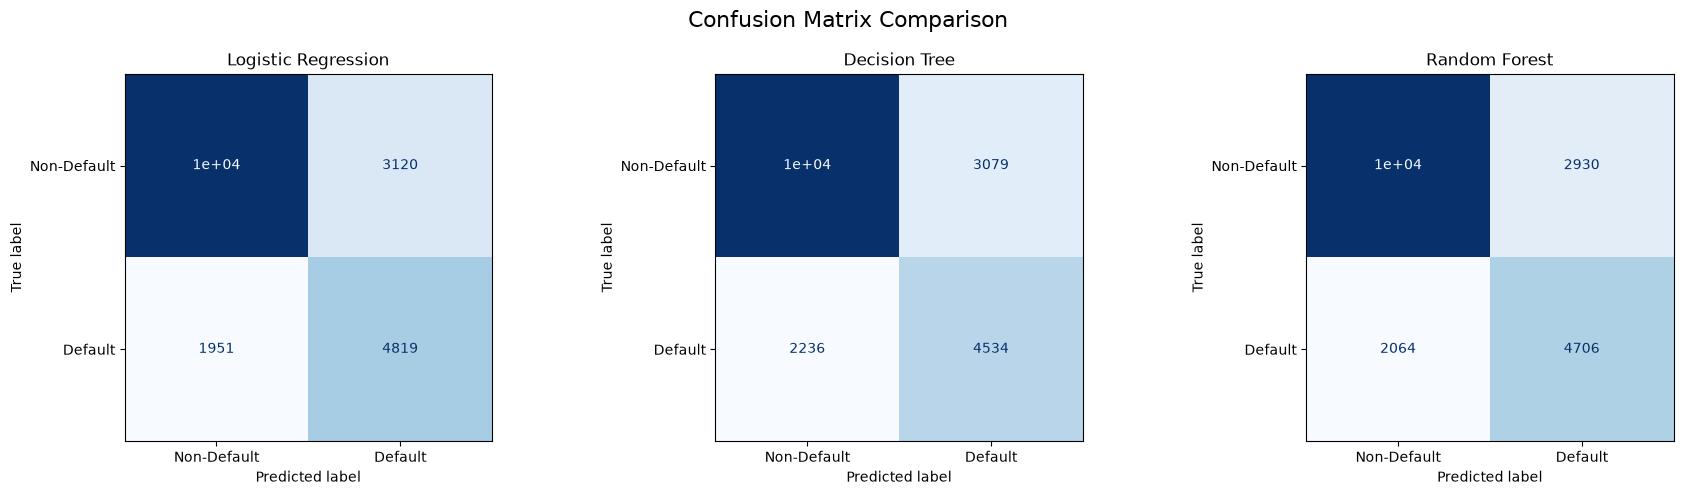

In [10]:
# Step 8.4 - Confusion Matrix Visualisation

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Store model predictions
model_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf
}

# Create three confusion matrix plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, predictions) in zip(
    axes, model_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Non-Default", "Default"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(model_name)

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()

## Step 8.5 - Random Forest Feature Importance

Identify and visualise the most important features used by the Random Forest model.

TOP 15 IMPORTANT FEATURES


,Feature,Importance
15,debt_to_income_ratio,0.2806
6,credit_score,0.1077
14,monthly_emi_lkr,0.1038
13,interest_rate_pct,0.0858
12,loan_term_months,0.0608
11,loan_amount_lkr,0.0534
3,monthly_income_lkr,0.0363
2,annual_income_lkr,0.0361
8,previous_defaults,0.0274
10,credit_utilization,0.0254


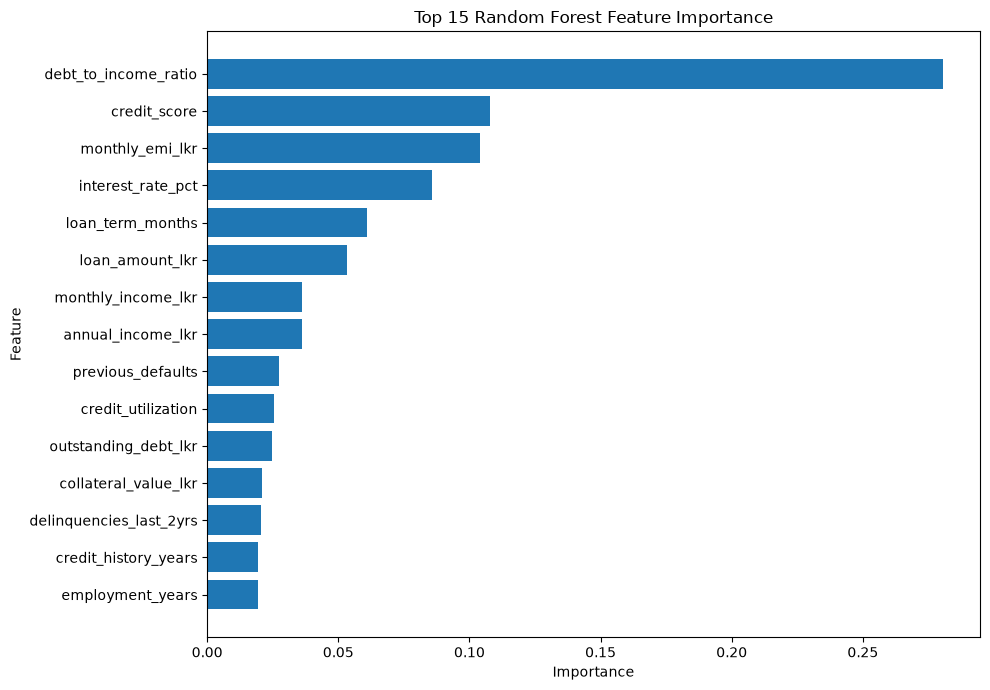

In [11]:
# Step 8.5 - Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("TOP 15 IMPORTANT FEATURES")

display(feature_importance.head(15).round(4))

# Plot top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# 05 - Hyperparameter Tuning

## Step 9.1 - Random Forest Hyperparameter Tuning

Use RandomizedSearchCV with cross-validation to identify better Random Forest hyperparameters.

The optimisation metric is Average Precision (PR-AUC).

In [3]:
# Step 9.1 - Random Forest Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Define hyperparameter search space
param_distributions = {
    "n_estimators": [100, 150, 200, 250],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [10, 20, 30],
    "min_samples_leaf": [5, 10, 15],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

# Create base Random Forest model
rf_base_model = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Configure RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_base_model,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="average_precision",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Run hyperparameter search using training data only
print("Starting Random Forest Hyperparameter Tuning...")

random_search.fit(X_train, y_train)

print("\nHyperparameter Tuning Completed!")

# Display best parameters
print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(round(random_search.best_score_, 4))

Starting Random Forest Hyperparameter Tuning...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Hyperparameter Tuning Completed!

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}

Best Cross-Validation PR-AUC:
0.7211


## Step 9.2 - Train Optimised Random Forest Model

Train a new Random Forest model using the best hyperparameters identified through RandomizedSearchCV.

In [4]:
# Step 9.2 - Train Optimised Random Forest Model

# Get the best model from RandomizedSearchCV
best_rf_model = random_search.best_estimator_

print("Training Optimised Random Forest Model...")

# Train the best model on the complete training dataset
best_rf_model.fit(X_train, y_train)

print("Optimised Random Forest Training Completed!")

# Generate predictions
y_pred_best_rf = best_rf_model.predict(X_test)

# Generate probabilities
y_prob_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

Training Optimised Random Forest Model...
Optimised Random Forest Training Completed!


In [8]:
joblib.dump(
    best_rf_model,
    MODEL_DIR / "best_random_forest.pkl"
)

print("Optimised Random Forest model saved successfully!")

Optimised Random Forest model saved successfully!


In [5]:
# Step 9.3 - Evaluate Optimised Random Forest

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Calculate metrics
print("OPTIMISED RANDOM FOREST RESULTS")

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred_best_rf), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_best_rf), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, y_prob_best_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_rf))

OPTIMISED RANDOM FOREST RESULTS

Accuracy: 0.7514
ROC-AUC: 0.813
PR-AUC: 0.7223

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.81     13230
           1       0.62      0.69      0.65      6770

    accuracy                           0.75     20000
   macro avg       0.73      0.74      0.73     20000
weighted avg       0.76      0.75      0.75     20000


Confusion Matrix:
[[10383  2847]
 [ 2124  4646]]


## Step 9.4 - Final Model Comparison

Compare baseline models and the optimised Random Forest model using classification and probability-based evaluation metrics.

In [7]:
# Reload trained models and regenerate predictions

import joblib
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Locate model directory
MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"

# Load original trained models
logistic_model = joblib.load(
    MODEL_DIR / "logistic_regression.pkl"
)

decision_tree_model = joblib.load(
    MODEL_DIR / "decision_tree.pkl"
)

random_forest_model = joblib.load(
    MODEL_DIR / "random_forest.pkl"
)

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test)
y_pred_tree = decision_tree_model.predict(X_test)
y_pred_rf = random_forest_model.predict(X_test)

# Generate probabilities
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Load optimised model
best_rf_model = joblib.load(
    MODEL_DIR / "random_forest.pkl"
) if not (MODEL_DIR / "best_random_forest.pkl").exists() else joblib.load(
    MODEL_DIR / "best_random_forest.pkl"
)

# Generate optimised predictions if saved model exists
if (MODEL_DIR / "best_random_forest.pkl").exists():
    y_pred_best_rf = best_rf_model.predict(X_test)
    y_prob_best_rf = best_rf_model.predict_proba(X_test)[:, 1]
else:
    print("Optimised model file not found.")
    print("Please rerun Step 9.1 and Step 9.2 to recreate it.")

print("Original model predictions regenerated successfully!")
print("Logistic Regression:", len(y_pred_logistic))
print("Decision Tree:", len(y_pred_tree))
print("Random Forest:", len(y_pred_rf))

Optimised model file not found.
Please rerun Step 9.1 and Step 9.2 to recreate it.
Original model predictions regenerated successfully!
Logistic Regression: 20000
Decision Tree: 20000
Random Forest: 20000


In [9]:
# Step 9.4 - Final Model Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Define all models and predictions
final_models = {
    "Logistic Regression": (y_pred_logistic, logistic_model.predict_proba(X_test)[:, 1]),
    "Decision Tree": (y_pred_tree, decision_tree_model.predict_proba(X_test)[:, 1]),
    "Random Forest": (y_pred_rf, random_forest_model.predict_proba(X_test)[:, 1]),
    "Optimised Random Forest": (y_pred_best_rf, y_prob_best_rf)
}

comparison_results = []

for model_name, (predictions, probabilities) in final_models.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Default_Precision": precision_score(y_test, predictions),
        "Default_Recall": recall_score(y_test, predictions),
        "Default_F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    })

# Create comparison table
final_comparison = pd.DataFrame(comparison_results)

final_comparison = final_comparison.sort_values(
    by="PR_AUC",
    ascending=False
)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(final_comparison.round(4))

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Default_Precision,Default_Recall,Default_F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.7464,0.6070,0.7118,0.6552,0.8175,0.7294
3,Optimised Random Forest,0.7514,0.6200,0.6863,0.6515,0.8130,0.7223
2,Random Forest,0.7503,0.6163,0.6951,0.6533,0.8135,0.7221
1,Decision Tree,0.7342,0.5956,0.6697,0.6305,0.7892,0.6818


# 06 - Final Model Selection

## Step 10.1 - Save Final Selected Model

Select Logistic Regression based on the comparative evaluation results and save it as the final model.

In [10]:
# Step 10.1 - Save Final Selected Model

import joblib
from pathlib import Path

# Define model directory
MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Select Logistic Regression
final_model = logistic_model

# Save final model
joblib.dump(
    final_model,
    MODEL_DIR / "final_model.pkl"
)

print("Final model saved successfully!")
print("\nSelected Model: Logistic Regression")
print("Model Path:", MODEL_DIR / "final_model.pkl")

Final model saved successfully!

Selected Model: Logistic Regression
Model Path: c:\Users\Admin\Desktop\Projects\Banking-Loan-Default-Prediction-ML\artifacts\models\final_model.pkl
